In [ ]:
# PROYECTO: EL DETECTIVE DE SEÑALES
# FASE 1: GENERACIÓN Y PREPARACIÓN DE DATOS

# Importar las librerías necesarias

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.model_selection import train_test_split

print("Librerías importadas correctamente")
print("Proyecto: El Detective de Señales")
print("Entorno configurado correctamente")

Librerías importadas correctamente
Proyecto: El Detective de Señales
Entorno configurado correctamente


In [ ]:
# ACTIVIDAD 1.2: DEFINIR LOS PARÁMETROS DE LA SEÑAL

# Frecuencia de muestreo
fs = 10000

# Frecuencia portadora
fc = 1000

# Tasa de símbolos
Rs = 100

# Duración de la señal
duracion = 0.1

# Crear el vector de tiempo
t = np.arange(0, duracion, 1/fs)

# Mostrar los parámetros
print("PARÁMETROS DE LA SEÑAL")
print("----------------------------")
print("Frecuencia de muestreo:", fs, "Hz")
print("Frecuencia portadora:", fc, "Hz")
print("Tasa de símbolos:", Rs, "símbolos/s")
print("Duración:", duracion, "segundos")
print("Número de muestras:", len(t))

PARÁMETROS DE LA SEÑAL
----------------------------
Frecuencia de muestreo: 10000 Hz
Frecuencia portadora: 1000 Hz
Tasa de símbolos: 100 símbolos/s
Duración: 0.1 segundos
Número de muestras: 1000


Bits generados: [0 1 0 0 1 0 1 0 0 0]


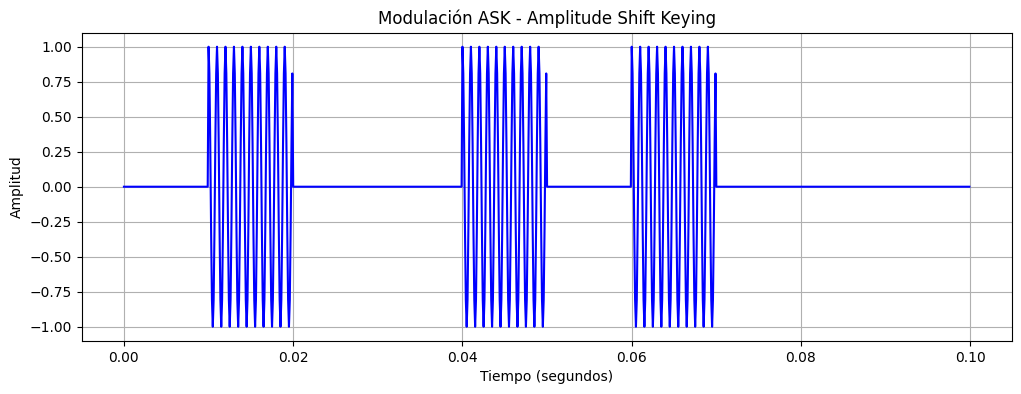

In [ ]:
# ACTIVIDAD 1.3: GENERACIÓN DE SEÑALES
# MODULACIÓN ASK

# Función para generar una señal ASK
def generar_ask(bits):

    muestras_simbolo = int(fs / Rs)

    amplitudes = np.repeat(bits, muestras_simbolo)

    tiempo = np.arange(len(amplitudes)) / fs

    senal = amplitudes * np.cos(2 * np.pi * fc * tiempo)

    return senal


# Generar 10 bits aleatorios
bits = np.random.randint(0, 2, 10)

# Crear la señal ASK
senal_ask = generar_ask(bits)

# Mostrar los bits generados
print("Bits generados:", bits)

# Graficar la señal ASK
plt.figure(figsize=(12, 4))

plt.plot(t, senal_ask, color="blue")

plt.title("Modulación ASK - Amplitude Shift Keying")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.grid(True)

plt.show()

Bits generados: [0 1 0 0 1 0 1 0 0 0]


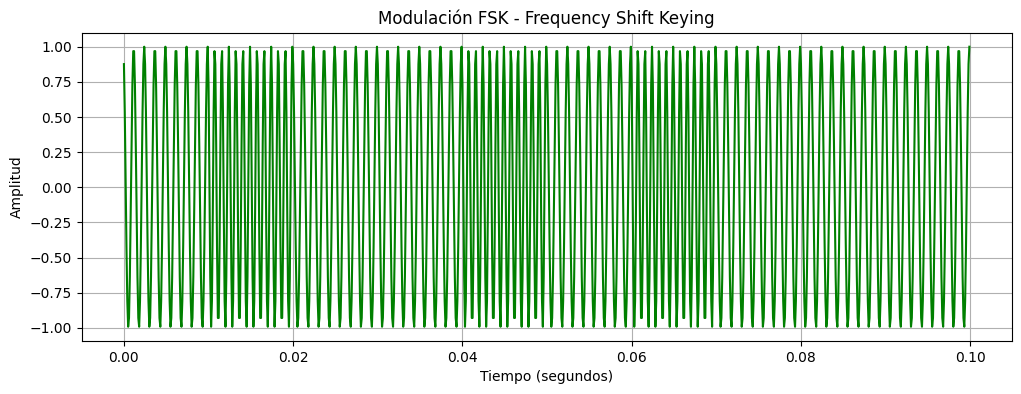

In [ ]:
# ACTIVIDAD 1.3: GENERACIÓN DE SEÑALES
# MODULACIÓN FSK

# Función para generar una señal FSK
def generar_fsk(bits):

    muestras_simbolo = int(fs / Rs)

    # Definir las frecuencias para los bits
    frecuencias = np.repeat(
        np.where(bits == 0, 800, 1200),
        muestras_simbolo
    )

    # Calcular la fase de la señal
    fase = 2 * np.pi * np.cumsum(frecuencias) / fs

    # Generar la señal FSK
    senal = np.cos(fase)

    return senal


# Utilizar los mismos bits de ASK
senal_fsk = generar_fsk(bits)

# Mostrar los bits
print("Bits generados:", bits)

# Graficar la señal FSK
plt.figure(figsize=(12, 4))

plt.plot(t, senal_fsk, color="green")

plt.title("Modulación FSK - Frequency Shift Keying")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.grid(True)

plt.show()

Bits generados: [0 1 0 0 1 0 1 0 0 0]


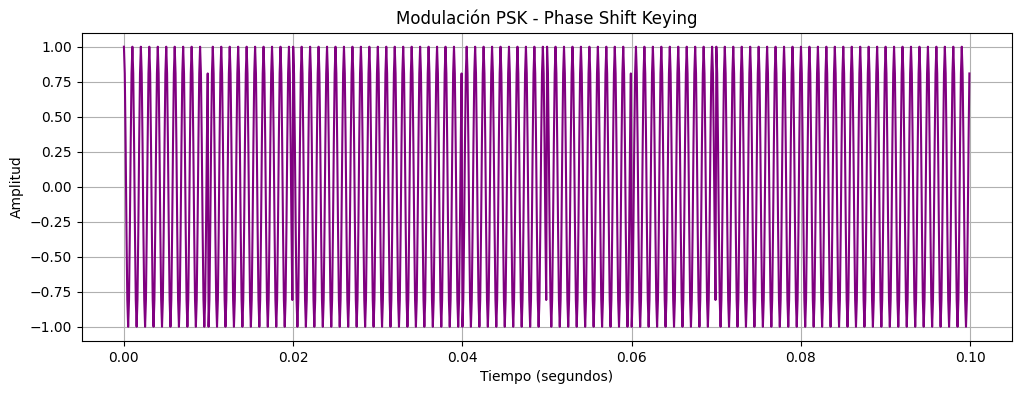

In [ ]:
# ACTIVIDAD 1.3: GENERACIÓN DE SEÑALES
# MODULACIÓN PSK

# Función para generar una señal PSK
def generar_psk(bits):

    muestras_simbolo = int(fs / Rs)

    # Definir la fase según los bits
    fases = np.repeat(bits * np.pi, muestras_simbolo)

    # Crear el vector de tiempo
    tiempo = np.arange(len(fases)) / fs

    # Generar la señal PSK
    senal = np.cos(2 * np.pi * fc * tiempo + fases)

    return senal


# Utilizar los mismos bits anteriores
senal_psk = generar_psk(bits)

# Mostrar los bits generados
print("Bits generados:", bits)

# Graficar la señal PSK
plt.figure(figsize=(12, 4))

plt.plot(t, senal_psk, color="purple")

plt.title("Modulación PSK - Phase Shift Keying")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.grid(True)

plt.show()

Símbolos generados: [ 2  6  1  1 13  4 14  9 12  3]


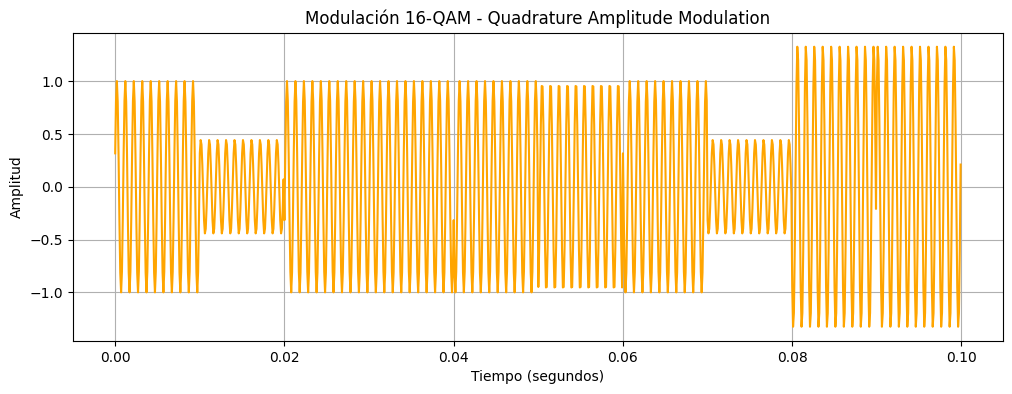

In [ ]:
# ACTIVIDAD 1.3: GENERACIÓN DE SEÑALES
# MODULACIÓN 16-QAM

# Función para generar una señal 16-QAM
def generar_qam(simbolos):

    muestras_simbolo = int(fs / Rs)

    # Definir los niveles de amplitud
    niveles = np.array([-3, -1, 1, 3])

    # Componentes I y Q
    i = niveles[simbolos % 4]
    q = niveles[simbolos // 4]

    # Repetir cada símbolo
    i = np.repeat(i, muestras_simbolo)
    q = np.repeat(q, muestras_simbolo)

    # Crear vector de tiempo
    tiempo = np.arange(len(i)) / fs

    # Generar señal QAM
    senal = (
        i * np.cos(2 * np.pi * fc * tiempo)
        - q * np.sin(2 * np.pi * fc * tiempo)
    )

    # Normalizar la potencia
    senal = senal / np.sqrt(10)

    return senal


# Generar 10 símbolos aleatorios
simbolos = np.random.randint(0, 16, 10)

# Crear señal QAM
senal_qam = generar_qam(simbolos)

# Mostrar símbolos
print("Símbolos generados:", simbolos)

# Graficar señal QAM
plt.figure(figsize=(12, 4))

plt.plot(t, senal_qam, color="orange")

plt.title("Modulación 16-QAM - Quadrature Amplitude Modulation")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.grid(True)

plt.show()

In [ ]:
# ACTIVIDAD 1.4: GENERACIÓN DEL CONJUNTO DE DATOS

# Listas para almacenar las señales y sus etiquetas
X = []
y = []

# Tipos de modulación
modulaciones = ["ASK", "FSK", "PSK", "QAM"]

# Generar 1000 señales de cada tipo
for modulacion in modulaciones:

    for n in range(1000):

        if modulacion == "ASK":
            bits = np.random.randint(0, 2, 10)
            senal = generar_ask(bits)

        elif modulacion == "FSK":
            bits = np.random.randint(0, 2, 10)
            senal = generar_fsk(bits)

        elif modulacion == "PSK":
            bits = np.random.randint(0, 2, 10)
            senal = generar_psk(bits)

        elif modulacion == "QAM":
            simbolos = np.random.randint(0, 16, 10)
            senal = generar_qam(simbolos)

        # Guardar la señal y su etiqueta
        X.append(senal)
        y.append(modulacion)

# Convertir las listas en arreglos de NumPy
X = np.array(X)
y = np.array(y)

# Mostrar resultados
print("CONJUNTO DE DATOS GENERADO")
print("------------------------------")
print("Total de señales:", len(X))
print("Muestras por señal:", X.shape[1])

# Mostrar cantidad de señales por modulación
for modulacion in modulaciones:
    cantidad = np.sum(y == modulacion)
    print(modulacion, ":", cantidad, "señales")

CONJUNTO DE DATOS GENERADO
------------------------------
Total de señales: 4000
Muestras por señal: 1000
ASK : 1000 señales
FSK : 1000 señales
PSK : 1000 señales
QAM : 1000 señales


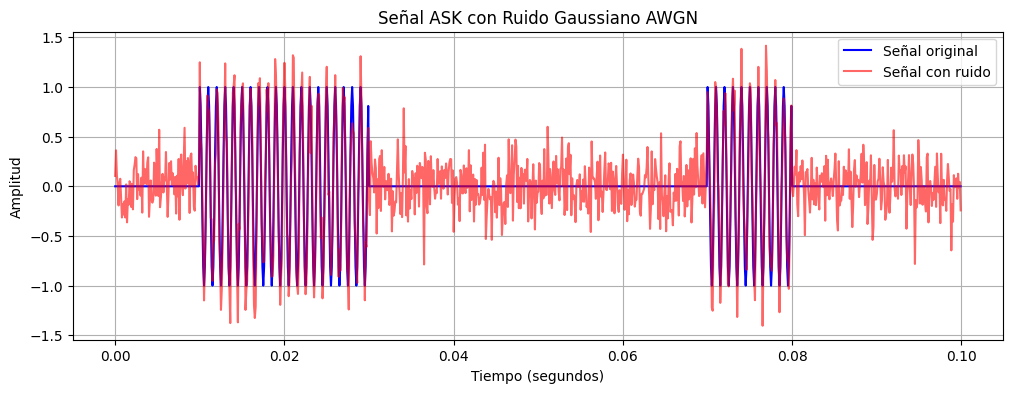

In [ ]:
# ACTIVIDAD 1.5: AGREGAR RUIDO GAUSSIANO (AWGN)

# Función para agregar ruido a una señal
def agregar_ruido(senal, snr_db):

    # Calcular la potencia de la señal
    potencia_senal = np.mean(senal ** 2)

    # Convertir SNR de decibeles a escala lineal
    snr_lineal = 10 ** (snr_db / 10)

    # Calcular la potencia del ruido
    potencia_ruido = potencia_senal / snr_lineal

    # Generar ruido gaussiano
    ruido = np.random.normal(
        0,
        np.sqrt(potencia_ruido),
        len(senal)
    )

    # Sumar el ruido a la señal original
    senal_ruidosa = senal + ruido

    return senal_ruidosa


# Seleccionar una señal ASK del dataset
senal_original = X[0]

# Agregar ruido con SNR de 5 dB
senal_con_ruido = agregar_ruido(senal_original, 5)

# Graficar ambas señales
plt.figure(figsize=(12, 4))

plt.plot(
    t,
    senal_original,
    color="blue",
    label="Señal original"
)

plt.plot(
    t,
    senal_con_ruido,
    color="red",
    alpha=0.6,
    label="Señal con ruido"
)

plt.title("Señal ASK con Ruido Gaussiano AWGN")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Amplitud")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# ACTIVIDAD 1.5: AGREGAR RUIDO A LAS 4000 SEÑALES

# Definir los niveles de SNR
niveles_snr = [0, 5, 10, 15, 20]

# Lista para guardar las señales con ruido
X_ruido = []

# Lista para guardar el nivel SNR de cada señal
snr_etiquetas = []

# Asignar niveles de ruido de manera equilibrada
snr_asignados = np.tile(niveles_snr, 800)

# Mezclar los niveles aleatoriamente
np.random.shuffle(snr_asignados)

# Agregar ruido a cada señal
for senal, snr in zip(X, snr_asignados):

    senal_ruidosa = agregar_ruido(senal, snr)

    X_ruido.append(senal_ruidosa)
    snr_etiquetas.append(snr)

# Convertir a arreglos NumPy
X_ruido = np.array(X_ruido)
snr_etiquetas = np.array(snr_etiquetas)

# Mostrar resultados
print("SEÑALES CON RUIDO GENERADAS")
print("--------------------------------")
print("Total de señales:", len(X_ruido))
print("Muestras por señal:", X_ruido.shape[1])

print("\nDISTRIBUCIÓN DE NIVELES SNR")

for snr in niveles_snr:
    cantidad = np.sum(snr_etiquetas == snr)
    print("SNR", snr, "dB:", cantidad, "señales")

SEÑALES CON RUIDO GENERADAS
--------------------------------
Total de señales: 4000
Muestras por señal: 1000

DISTRIBUCIÓN DE NIVELES SNR
SNR 0 dB: 800 señales
SNR 5 dB: 800 señales
SNR 10 dB: 800 señales
SNR 15 dB: 800 señales
SNR 20 dB: 800 señales


In [ ]:
# ACTIVIDAD 1.6: SEPARACIÓN DE DATOS

# Dividir los datos en entrenamiento (80%) y prueba (20%)

X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X_ruido,
    y,
    snr_etiquetas,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Mostrar los resultados
print("SEPARACIÓN DEL CONJUNTO DE DATOS")
print("------------------------------------")

print("Total de señales:", len(X_ruido))
print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

print("\nDISTRIBUCIÓN POR MODULACIÓN")

for modulacion in modulaciones:

    cantidad_train = np.sum(y_train == modulacion)
    cantidad_test = np.sum(y_test == modulacion)

    print(
        modulacion,
        "- Entrenamiento:", cantidad_train,
        "| Prueba:", cantidad_test
    )

SEPARACIÓN DEL CONJUNTO DE DATOS
------------------------------------
Total de señales: 4000
Datos de entrenamiento: 3200
Datos de prueba: 800

DISTRIBUCIÓN POR MODULACIÓN
ASK - Entrenamiento: 800 | Prueba: 200
FSK - Entrenamiento: 800 | Prueba: 200
PSK - Entrenamiento: 800 | Prueba: 200
QAM - Entrenamiento: 800 | Prueba: 200


In [ ]:
# GUARDAR EL CONJUNTO DE DATOS
# PROYECTO: EL DETECTIVE DE SEÑALES

# Guardar señales, etiquetas y niveles de ruido
np.savez_compressed(
    "Dataset_Detective_de_Senales.npz",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    snr_train=snr_train,
    snr_test=snr_test
)

print("================================")
print("DATASET GUARDADO CORRECTAMENTE")
print("================================")
print("Archivo: Dataset_Detective_de_Senales.npz")
print("Señales de entrenamiento:", len(X_train))
print("Señales de prueba:", len(X_test))
print("Total de señales:", len(X_train) + len(X_test))

DATASET GUARDADO CORRECTAMENTE
Archivo: Dataset_Detective_de_Senales.npz
Señales de entrenamiento: 3200
Señales de prueba: 800
Total de señales: 4000


In [ ]:
# FASE 2: DISEÑO Y ENTRENAMIENTO DEL MODELO
# PASO 1: CARGAR EL DATASET

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models

# Cargar las señales guardadas en la Fase 1
datos = np.load("Dataset_Detective_de_Senales.npz")

# Recuperar datos de entrenamiento y prueba
X_train = datos["X_train"]
X_test = datos["X_test"]

# Recuperar etiquetas de las modulaciones
y_train = datos["y_train"]
y_test = datos["y_test"]

# Mostrar resultados
print("FASE 2: DATOS CARGADOS CORRECTAMENTE")
print("------------------------------------")
print("Señales de entrenamiento:", X_train.shape)
print("Señales de prueba:", X_test.shape)
print("Tipos de modulación:", np.unique(y_train))

FASE 2: DATOS CARGADOS CORRECTAMENTE
------------------------------------
Señales de entrenamiento: (3200, 1000)
Señales de prueba: (800, 1000)
Tipos de modulación: ['ASK' 'FSK' 'PSK' 'QAM']


In [ ]:
# FASE 2: PREPARACIÓN DE DATOS PARA LA CNN

# Convertir las señales a formato compatible con Conv1D
X_train_cnn = X_train.reshape(3200, 1000, 1)
X_test_cnn = X_test.reshape(800, 1000, 1)

# Convertir los datos a tipo float32
X_train_cnn = X_train_cnn.astype("float32")
X_test_cnn = X_test_cnn.astype("float32")

# Convertir las etiquetas a números
etiquetas = {"ASK": 0, "FSK": 1, "PSK": 2, "QAM": 3}

y_train_num = np.array([etiquetas[x] for x in y_train])
y_test_num = np.array([etiquetas[x] for x in y_test])

# Mostrar resultados
print("DATOS PREPARADOS PARA LA RED NEURONAL")
print("--------------------------------------")
print("Entrenamiento:", X_train_cnn.shape)
print("Prueba:", X_test_cnn.shape)
print("Etiquetas numéricas:", np.unique(y_train_num))

DATOS PREPARADOS PARA LA RED NEURONAL
--------------------------------------
Entrenamiento: (3200, 1000, 1)
Prueba: (800, 1000, 1)
Etiquetas numéricas: [0 1 2 3]


In [ ]:
# FASE 2: ACTIVIDAD 2.2
# DISEÑO DE LA RED NEURONAL CONVOLUCIONAL (CNN)

from tensorflow.keras import layers, models

# Crear el modelo
modelo = models.Sequential([

    # Capa de entrada
    layers.Input(shape=(1000, 1)),

    # Primera capa convolucional
    layers.Conv1D(32, kernel_size=5, activation="relu"),

    # Reducir el tamaño de los datos
    layers.MaxPooling1D(pool_size=2),

    # Segunda capa convolucional
    layers.Conv1D(64, kernel_size=5, activation="relu"),

    # Segunda reducción
    layers.MaxPooling1D(pool_size=2),

    # Convertir los datos en un vector
    layers.Flatten(),

    # Capa neuronal
    layers.Dense(64, activation="relu"),

    # Capa de salida con 4 neuronas
    layers.Dense(4, activation="softmax")

])

# Mostrar la estructura del modelo
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 996, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 498, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 494, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 247, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 15808)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,011,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,022,532 (3.90 MB)

 Trainable params: 1,022,532 (3.90 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# FASE 2: ACTIVIDAD 2.3
# COMPILACIÓN DE LA RED NEURONAL

# Configurar el modelo
modelo.compile(

    # Optimizador
    optimizer="adam",

    # Función de pérdida
    loss="sparse_categorical_crossentropy",

    # Métrica de evaluación
    metrics=["accuracy"]

)

# Mostrar mensaje de confirmación
print("MODELO COMPILADO CORRECTAMENTE")
print("--------------------------------")
print("Optimizador: Adam")
print("Función de pérdida: Sparse Categorical Crossentropy")
print("Métrica: Accuracy")
print("Número de clases: 4")

MODELO COMPILADO CORRECTAMENTE
--------------------------------
Optimizador: Adam
Función de pérdida: Sparse Categorical Crossentropy
Métrica: Accuracy
Número de clases: 4


In [ ]:
# FASE 2: ACTIVIDAD 2.4
# ENTRENAMIENTO DE LA RED NEURONAL CNN

# Entrenar el modelo
historial = modelo.fit(

    # Señales de entrenamiento
    X_train_cnn,

    # Etiquetas correctas
    y_train_num,

    # Número de épocas
    epochs=10,

    # Cantidad de señales por lote
    batch_size=32,

    # Porcentaje de datos para validación
    validation_split=0.2,

    # Mostrar el progreso
    verbose=1
)

print("================================")
print("ENTRENAMIENTO FINALIZADO")
print("================================")

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.8816 - loss: 0.3905 - val_accuracy: 0.9953 - val_loss: 0.0296
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.9949 - loss: 0.0246 - val_accuracy: 0.9984 - val_loss: 0.0105
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9980 - loss: 0.0095 - val_accuracy: 1.0000 - val_loss: 0.0048
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - accuracy: 0.9984 - loss: 0.0067 - val_accuracy: 1.0000 - val_loss: 0.0056
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9988 - loss: 0.0040 - val_accuracy: 0.9969 - val_loss: 0.0190
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - accuracy: 0.9984 - loss: 0.0043 - val_accuracy: 0.9984 - val_loss: 0.0056
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - accuracy: 0.9984 - loss: 0.0075 - val_accuracy: 0.9969 - val_loss: 0.0162
Epoch 8/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 11s 75ms/step - accuracy: 0.9973 - loss: 0.0097 - val_accuracy: 0.9937 - 

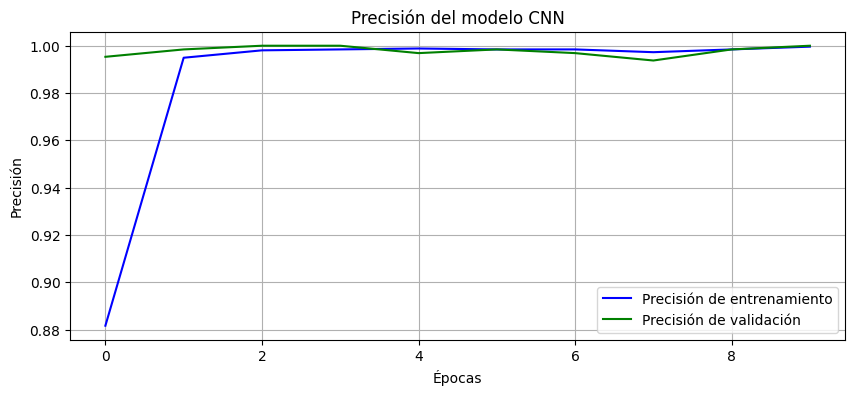

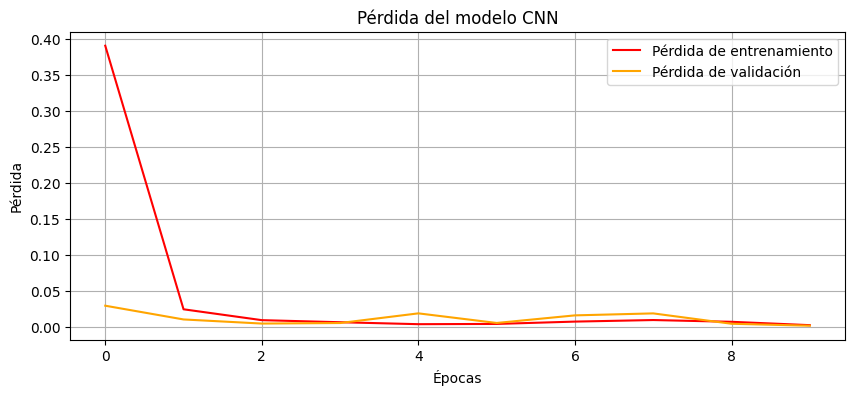

In [ ]:
# FASE 2: GRÁFICAS DEL ENTRENAMIENTO

import matplotlib.pyplot as plt

# Gráfica de precisión
plt.figure(figsize=(10, 4))

plt.plot(historial.history["accuracy"],
         label="Precisión de entrenamiento",
         color="blue")

plt.plot(historial.history["val_accuracy"],
         label="Precisión de validación",
         color="green")

plt.title("Precisión del modelo CNN")
plt.xlabel("Épocas")
plt.ylabel("Precisión")
plt.legend()
plt.grid(True)

plt.show()


# Gráfica de pérdida
plt.figure(figsize=(10, 4))

plt.plot(historial.history["loss"],
         label="Pérdida de entrenamiento",
         color="red")

plt.plot(historial.history["val_loss"],
         label="Pérdida de validación",
         color="orange")

plt.title("Pérdida del modelo CNN")
plt.xlabel("Épocas")
plt.ylabel("Pérdida")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# FASE 2: EVALUACIÓN DEL MODELO CNN

# Evaluar con las señales de prueba
perdida, precision = modelo.evaluate(
    X_test_cnn,
    y_test_num,
    verbose=1
)

# Mostrar resultados
print("================================")
print("RESULTADOS DE LA EVALUACIÓN")
print("================================")

print("Total de señales evaluadas:", len(X_test_cnn))
print("Precisión del modelo:", round(precision * 100, 2), "%")
print("Pérdida del modelo:", round(perdida, 4))

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 1.0000 - loss: 0.0017
RESULTADOS DE LA EVALUACIÓN
Total de señales evaluadas: 800
Precisión del modelo: 100.0 %
Pérdida del modelo: 0.0017


In [ ]:
# FASE 2: ACTIVIDAD 2.5
# GUARDAR EL MODELO ENTRENADO

# Nombre del archivo
nombre_archivo = "Modelo_Detective_de_Senales.keras"

# Guardar la red neuronal
modelo.save(nombre_archivo)

# Mostrar confirmación
print("====================================")
print("MODELO GUARDADO CORRECTAMENTE")
print("====================================")
print("Archivo:", nombre_archivo)
print("Tipo de modelo: CNN 1D")
print("Modulaciones: ASK, FSK, PSK y QAM")
print("Número de clases: 4")

MODELO GUARDADO CORRECTAMENTE
Archivo: Modelo_Detective_de_Senales.keras
Tipo de modelo: CNN 1D
Modulaciones: ASK, FSK, PSK y QAM
Número de clases: 4
